<a href="https://colab.research.google.com/github/ZofiaLandowska/notes/blob/main/site/en/tutorials/keras/classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Zofia Landowska
### CSC 483 Section 701
### Homework #4: Written exercises + Keras Experiment

In [1]:
# TensorFlow and tf.keras
import tensorflow as tf

# Helper libraries
import matplotlib.pyplot as plt

print(tf.__version__)

2.21.0


In [2]:
# Set the seed
tf.keras.utils.set_random_seed(43)

## Import the Fashion MNIST dataset

In [3]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Preprocess the data


Pixel values are scaled from 0-255 to 0-1 so that training is more stable.

In [4]:
train_images = train_images / 255.0

test_images = test_images / 255.0

## Build the models

### Original Model


In [5]:
model_01 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [6]:
model_01.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [7]:
history_01 = model_01.fit(train_images, train_labels, epochs=10,
                          validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8262 - loss: 0.4975 - val_accuracy: 0.8539 - val_loss: 0.4142
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8644 - loss: 0.3745 - val_accuracy: 0.8656 - val_loss: 0.3813
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8769 - loss: 0.3357 - val_accuracy: 0.8712 - val_loss: 0.3626
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8853 - loss: 0.3115 - val_accuracy: 0.8740 - val_loss: 0.3569
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8921 - loss: 0.2918 - val_accuracy: 0.8743 - val_loss: 0.3502
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8978 - loss: 0.2757 - val_accuracy: 0.8769 - val_loss: 0.3465
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9027 - loss: 0.2618 - val_accuracy: 0.8748 - val_loss: 0.3540
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9068 - loss: 0.2503 - 

### Evaluate accuracy

In [8]:
test_loss, test_acc = model_01.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_01 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8779 - loss: 0.3539

Model_01 test accuracy: 0.8779000043869019


The accuracy on the test dataset is lower than the accuracy on the training dataset. This gap between training accuracy and test accuracy represents overfitting.

### New Model with an Additional Dense Layer of size 88

In [9]:
model_02 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(88, activation='relu'),
    tf.keras.layers.Dense(10)
])

In [10]:
model_02.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [11]:
history_02 = model_02.fit(train_images, train_labels, epochs=10,
                          validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8274 - loss: 0.4854 - val_accuracy: 0.8597 - val_loss: 0.3973
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8665 - loss: 0.3658 - val_accuracy: 0.8683 - val_loss: 0.3717
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8780 - loss: 0.3311 - val_accuracy: 0.8744 - val_loss: 0.3585
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8867 - loss: 0.3064 - val_accuracy: 0.8745 - val_loss: 0.3532
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8928 - loss: 0.2876 - val_accuracy: 0.8778 - val_loss: 0.3549
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8978 - loss: 0.2719 - val_accuracy: 0.8773 - val_loss: 0.3595
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9036 - loss: 0.2589 - val_accuracy: 0.8806 - val_loss: 0.3480
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9082 - loss: 0.2460 - 

### Evaluate accuracy

In [12]:
test_loss, test_acc = model_02.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_02 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8830 - loss: 0.3550

Model_02 test accuracy: 0.8830000162124634


Training accuracy is about 91% and test accuracy about 88%, which suggests mild overfitting.
The difference between Model_01 and Model_02 is simply random noise.

###New Model with an Additional Dense Layer of size 256

In [13]:
model_03 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(10)
])

In [14]:
model_03.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [15]:
history_03 = model_03.fit(train_images, train_labels, epochs=10,
                          validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8271 - loss: 0.4811 - val_accuracy: 0.8538 - val_loss: 0.4055
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8673 - loss: 0.3611 - val_accuracy: 0.8698 - val_loss: 0.3614
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8801 - loss: 0.3254 - val_accuracy: 0.8715 - val_loss: 0.3576
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8888 - loss: 0.3005 - val_accuracy: 0.8763 - val_loss: 0.3556
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8957 - loss: 0.2799 - val_accuracy: 0.8763 - val_loss: 0.3616
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9004 - loss: 0.2643 - val_accuracy: 0.8692 - val_loss: 0.3882
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9055 - loss: 0.2492 - val_accuracy: 0.8789 - val_loss: 0.3523
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9103 - loss: 0.2358 -

###Evaluate accuracy

In [16]:
test_loss, test_acc = model_03.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_03 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8779 - loss: 0.3871

Model_03 test accuracy: 0.8779000043869019


Results are very similar to the ones for Model_02 and the model is still slightly overfitting to the training data. Model_03 achieved a higher loss than the previous ones.

###New Model with an Additional Dense Layer of size 32

In [17]:
model_04 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10)
])

In [18]:
model_04.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [19]:
history_04 = model_04.fit(train_images, train_labels, epochs=10,
                          validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8219 - loss: 0.5010 - val_accuracy: 0.8508 - val_loss: 0.4184
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8648 - loss: 0.3735 - val_accuracy: 0.8594 - val_loss: 0.4016
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8773 - loss: 0.3377 - val_accuracy: 0.8709 - val_loss: 0.3739
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8853 - loss: 0.3143 - val_accuracy: 0.8726 - val_loss: 0.3636
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8907 - loss: 0.2955 - val_accuracy: 0.8763 - val_loss: 0.3568
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.8961 - loss: 0.2804 - val_accuracy: 0.8780 - val_loss: 0.3481
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9000 - loss: 0.2682 - val_accuracy: 0.8759 - val_loss: 0.3566
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9040 - loss: 0.2555 -

###Evaluate accuracy

In [20]:
test_loss, test_acc = model_04.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_04 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8785 - loss: 0.3727

Model_04 test accuracy: 0.8784999847412109


Model_04 achieved similar training and testing accuracies as well as a similar loss to the previous models. The slight changes may represent noise.

In [21]:
histories = {
    "original": history_01,
    "128+88":   history_02,
    "128+256":  history_03,
    "128+32":   history_04,
}

print("Model      | Train acc | Val acc | Val loss")
for name, h in histories.items():
    print(f"{name:10} | {h.history['accuracy'][-1]:.4f}    | "
          f"{h.history['val_accuracy'][-1]:.4f}  | {h.history['val_loss'][-1]:.4f}")

Model      | Train acc | Val acc | Val loss
original   | 0.9141    | 0.8779  | 0.3539
128+88     | 0.9152    | 0.8830  | 0.3550
128+256    | 0.9184    | 0.8779  | 0.3871
128+32     | 0.9107    | 0.8785  | 0.3727


None of the models with an extra layer gave a clear improvement. Test accuracies range from 0.8779 to 0.8830, which is within random noise. The original model has the lowest loss (0.3539) and is the simplest, so I will use it for the next experiments.

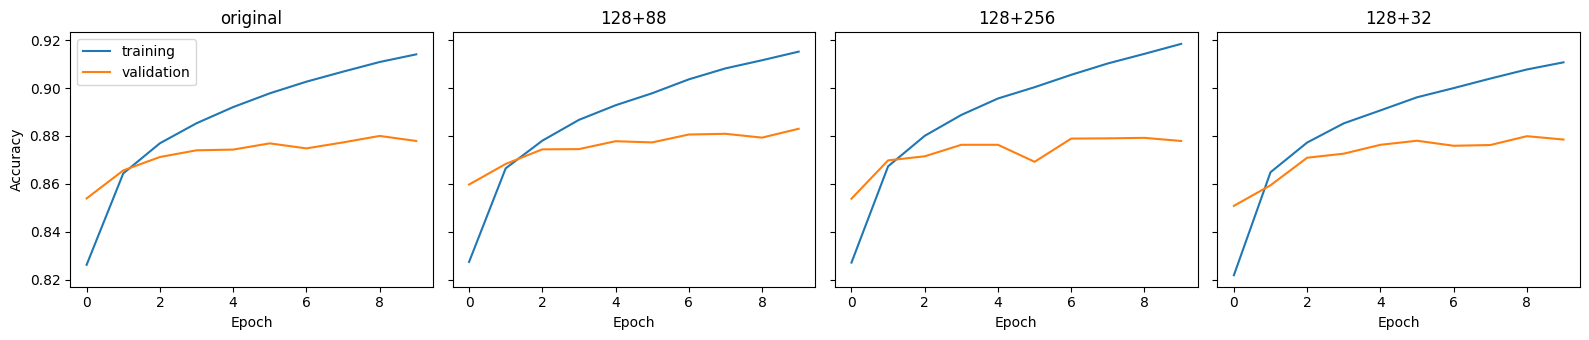

In [42]:
# Experiment A: training vs. validation accuracy
histories = {"original": history_01, "128+88": history_02,
             "128+256": history_03, "128+32": history_04}

fig, axes = plt.subplots(1, len(histories), figsize=(4*len(histories), 3.5), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history['accuracy'], label='training')
    ax.plot(h.history['val_accuracy'], label='validation')
    ax.set_title(name)
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
plt.tight_layout()
plt.show()

## Learning rate tuning

###Learning rate = 0.01

In [22]:
model_05 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.01)
model_05.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_05 = model_05.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8126 - loss: 0.5258 - val_accuracy: 0.8432 - val_loss: 0.4486
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8454 - loss: 0.4344 - val_accuracy: 0.8358 - val_loss: 0.4704
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8526 - loss: 0.4122 - val_accuracy: 0.8459 - val_loss: 0.4481
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8574 - loss: 0.4000 - val_accuracy: 0.8452 - val_loss: 0.4541
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8594 - loss: 0.3879 - val_accuracy: 0.8475 - val_loss: 0.4428
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8642 - loss: 0.3800 - val_accuracy: 0.8514 - val_loss: 0.4428
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8642 - loss: 0.3788 - val_accuracy: 0.8516 - val_loss: 0.4456
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8673 - loss: 0.3652 - 

In [23]:
test_loss, test_acc = model_05.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_05 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8539 - loss: 0.4425

Model_05 test accuracy: 0.8539000153541565


With a learning rate of 0.01 the model reached only 87% training accuracy and 85% test accuracy, and the highest loss so far: 0.4425. The steps are too large, so the weights overshoot the minimum instead of settling into it.

###Learning rate = 0.001

In [24]:
model_06 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_06.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_06 = model_06.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8270 - loss: 0.4931 - val_accuracy: 0.8567 - val_loss: 0.4079
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8657 - loss: 0.3713 - val_accuracy: 0.8700 - val_loss: 0.3712
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8771 - loss: 0.3334 - val_accuracy: 0.8730 - val_loss: 0.3590
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8874 - loss: 0.3090 - val_accuracy: 0.8775 - val_loss: 0.3446
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.8929 - loss: 0.2906 - val_accuracy: 0.8773 - val_loss: 0.3462
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8980 - loss: 0.2758 - val_accuracy: 0.8795 - val_loss: 0.3434
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9028 - loss: 0.2629 - val_accuracy: 0.8826 - val_loss: 0.3418
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.9073 - loss: 0.2507 - 

In [25]:
test_loss, test_acc = model_06.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_06 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8828 - loss: 0.3474

Model_06 test accuracy: 0.8827999830245972


Both the training and testing results improved with the smaller learning rate. The loss also decreased, which suggests that the previous learning rate was too large and the learning process omitted important information.

###Learning rate = 0.0001

In [26]:
model_07 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.0001)
model_07.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_07 = model_07.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7714 - loss: 0.7124 - val_accuracy: 0.8179 - val_loss: 0.5377
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8399 - loss: 0.4746 - val_accuracy: 0.8349 - val_loss: 0.4809
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8533 - loss: 0.4307 - val_accuracy: 0.8429 - val_loss: 0.4544
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8611 - loss: 0.4050 - val_accuracy: 0.8476 - val_loss: 0.4376
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8670 - loss: 0.3866 - val_accuracy: 0.8510 - val_loss: 0.4261
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8726 - loss: 0.3723 - val_accuracy: 0.8538 - val_loss: 0.4172
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8754 - loss: 0.3605 - val_accuracy: 0.8561 - val_loss: 0.4094
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8781 - loss: 0.3502 - 

In [27]:
test_loss, test_acc = model_07.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_07 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8614 - loss: 0.3936

Model_07 test accuracy: 0.8614000082015991


With a learning rate of 0.0001 the model is better than at 0.01 but worse than at 0.001 (88% training accuracy, 86% test accuracy). The steps are so small that after 10 epochs the model has not finished learning (underfitting). It would need more epochs.

In [28]:
histories = {
    "0.01": history_05,
    "0.001":   history_06,
    "0.0001":  history_07
}

print("Model      | Train acc | Val acc | Val loss")
for name, h in histories.items():
    print(f"{name:10} | {h.history['accuracy'][-1]:.4f}    | "
          f"{h.history['val_accuracy'][-1]:.4f}  | {h.history['val_loss'][-1]:.4f}")

Model      | Train acc | Val acc | Val loss
0.01       | 0.8712    | 0.8539  | 0.4425
0.001      | 0.9148    | 0.8828  | 0.3474
0.0001     | 0.8826    | 0.8614  | 0.3936


The model with a 0.001 learning rate performed the best, achieving a training accuracy of 91%, a test accuracy of 88%, and a loss of 0.3474.

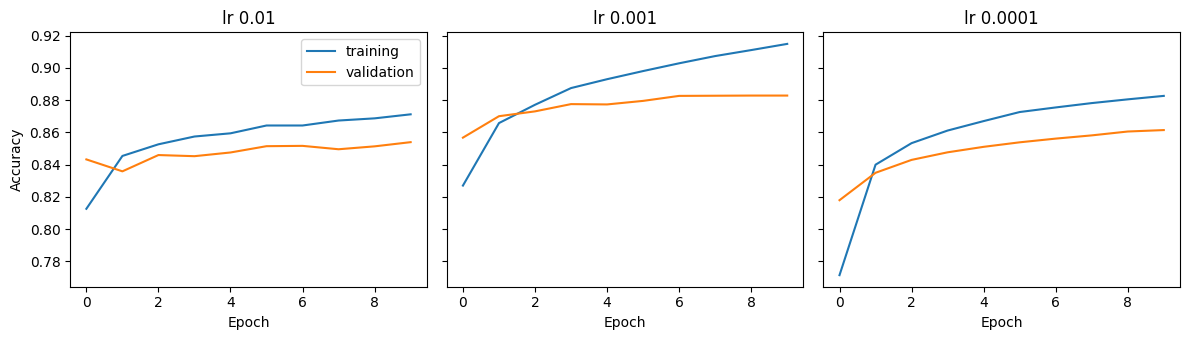

In [43]:
# Learning rate experiment: training vs. validation accuracy
histories = {"lr 0.01": history_05, "lr 0.001": history_06, "lr 0.0001": history_07}

fig, axes = plt.subplots(1, len(histories), figsize=(4*len(histories), 3.5), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history['accuracy'], label='training')
    ax.plot(h.history['val_accuracy'], label='validation')
    ax.set_title(name)
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
plt.tight_layout()
plt.show()

##Regularization methods

### L1(0.001) Regularization


In [29]:
model_08 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L1(0.001)),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_08.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_08 = model_08.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.7859 - loss: 1.2451 - val_accuracy: 0.8035 - val_loss: 0.8249
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8094 - loss: 0.7970 - val_accuracy: 0.8179 - val_loss: 0.7359
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8202 - loss: 0.7318 - val_accuracy: 0.8264 - val_loss: 0.6932
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.8275 - loss: 0.6963 - val_accuracy: 0.8298 - val_loss: 0.6718
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8317 - loss: 0.6719 - val_accuracy: 0.8325 - val_loss: 0.6540
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8344 - loss: 0.6561 - val_accuracy: 0.8337 - val_loss: 0.6433
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8374 - loss: 0.6427 - val_accuracy: 0.8372 - val_loss: 0.6330
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8398 - loss: 0.6294 -

In [30]:
test_loss, test_acc = model_08.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_08 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8378 - loss: 0.6169

Model_08 test accuracy: 0.8378000259399414


Training began and ended with lower accuracies (84% training, 84% test). The loss is much larger (0.6169), which suggests the penalty is too strong and the model is underfitting.

### L1(0.0001) Regularization

In [31]:
model_09 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L1(0.0001)),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_09.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_09 = model_09.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8185 - loss: 0.7506 - val_accuracy: 0.8485 - val_loss: 0.6089
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8502 - loss: 0.5734 - val_accuracy: 0.8557 - val_loss: 0.5514
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8597 - loss: 0.5255 - val_accuracy: 0.8577 - val_loss: 0.5299
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8649 - loss: 0.4983 - val_accuracy: 0.8584 - val_loss: 0.5167
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8690 - loss: 0.4774 - val_accuracy: 0.8617 - val_loss: 0.5065
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8712 - loss: 0.4641 - val_accuracy: 0.8613 - val_loss: 0.5025
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8748 - loss: 0.4528 - val_accuracy: 0.8618 - val_loss: 0.4899
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8770 - loss: 0.4433 - 

In [32]:
test_loss, test_acc = model_09.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_09 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8653 - loss: 0.4740

Model_09 test accuracy: 0.8652999997138977


Accuracy improved considerably (86.5% test), but the loss (0.4740) is still much higher than without a regularizer. Part of this is because Keras adds the penalty term to the loss, so these losses cannot be compared directly with the earlier ones.

### L2(0.001) Regularization

In [33]:
model_10 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L2(0.001)),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_10.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_10 = model_10.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8184 - loss: 0.6468 - val_accuracy: 0.8479 - val_loss: 0.5315
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8491 - loss: 0.5110 - val_accuracy: 0.8549 - val_loss: 0.4923
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.8561 - loss: 0.4790 - val_accuracy: 0.8556 - val_loss: 0.4852
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8600 - loss: 0.4607 - val_accuracy: 0.8586 - val_loss: 0.4697
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8642 - loss: 0.4492 - val_accuracy: 0.8561 - val_loss: 0.4715
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8677 - loss: 0.4404 - val_accuracy: 0.8572 - val_loss: 0.4658
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8698 - loss: 0.4322 - val_accuracy: 0.8610 - val_loss: 0.4600
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8708 - loss: 0.4264 -

In [34]:
test_loss, test_acc = model_10.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_10 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8647 - loss: 0.4497

Model_10 test accuracy: 0.8647000193595886


The loss is still high (0.4497), but accuracy (86.5% test) is better than with L1(0.001), and the gap between training and test accuracy is under 1 point, so there is less overfitting. The penalty still seems too strong.

### L2(0.0001) Regularization

In [35]:
model_11 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L2(0.0001)),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_11.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_11 = model_11.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8229 - loss: 0.5312 - val_accuracy: 0.8548 - val_loss: 0.4487
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8624 - loss: 0.4160 - val_accuracy: 0.8608 - val_loss: 0.4236
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8735 - loss: 0.3855 - val_accuracy: 0.8644 - val_loss: 0.4145
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8803 - loss: 0.3675 - val_accuracy: 0.8684 - val_loss: 0.4086
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8852 - loss: 0.3548 - val_accuracy: 0.8707 - val_loss: 0.4011
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8898 - loss: 0.3446 - val_accuracy: 0.8723 - val_loss: 0.4000
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8922 - loss: 0.3368 - val_accuracy: 0.8721 - val_loss: 0.4003
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8957 - loss: 0.3296 - 

In [36]:
test_loss, test_acc = model_11.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_11 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8780 - loss: 0.3936

Model_11 test accuracy: 0.878000020980835


This is the best regularized model: 90.0% training accuracy, 87.8% test accuracy, loss 0.3936. The gap between training and test accuracy is about 2.2 points, compared with about 3.2 points without a regularizer, so it overfits less.

In [37]:
histories = {
    "L1 0.001": history_08,
    "L1 0.0001":   history_09,
    "L2 0.001":  history_10,
    "L2 0.0001": history_11
}

print("Model      | Train acc | Val acc | Val loss")
for name, h in histories.items():
    print(f"{name:10} | {h.history['accuracy'][-1]:.4f}    | "
          f"{h.history['val_accuracy'][-1]:.4f}  | {h.history['val_loss'][-1]:.4f}")

Model      | Train acc | Val acc | Val loss
L1 0.001   | 0.8418    | 0.8378  | 0.6169
L1 0.0001  | 0.8805    | 0.8653  | 0.4740
L2 0.001   | 0.8732    | 0.8647  | 0.4497
L2 0.0001  | 0.8997    | 0.8780  | 0.3936


I chose L2(0.0001) because it had the highest accuracy and lowest loss of the regularized models and it reduced the gap between training and test accuracy. It did not beat the model without regularization on test accuracy (0.8780 vs. 0.8828), so its benefit is less overfitting, not higher accuracy. I will keep L2(0.0001) for the dropout experiment.

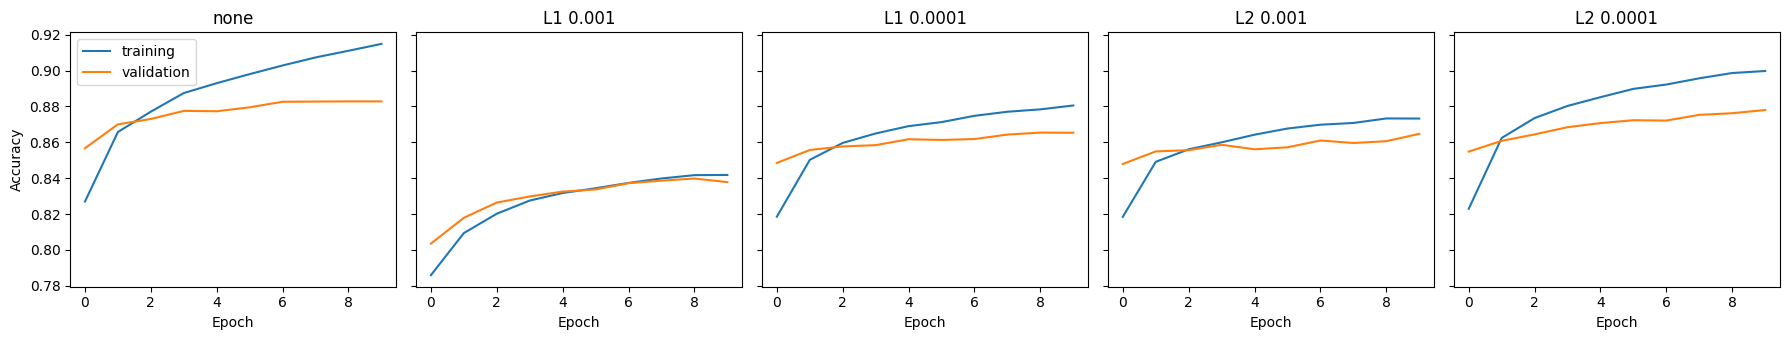

In [44]:
# Regularization experiment: training vs. validation accuracy
histories = {"none": history_06, "L1 0.001": history_08, "L1 0.0001": history_09,
             "L2 0.001": history_10, "L2 0.0001": history_11}

fig, axes = plt.subplots(1, len(histories), figsize=(3.6*len(histories), 3.5), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history['accuracy'], label='training')
    ax.plot(h.history['val_accuracy'], label='validation')
    ax.set_title(name)
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
plt.tight_layout()
plt.show()

###Dropout - remove 20% of the neurons in the last hidden layer

In [38]:
model_12 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L2(0.0001)),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_12.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_12 = model_12.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8118 - loss: 0.5600 - val_accuracy: 0.8451 - val_loss: 0.4577
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8514 - loss: 0.4416 - val_accuracy: 0.8558 - val_loss: 0.4378
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8625 - loss: 0.4170 - val_accuracy: 0.8592 - val_loss: 0.4252
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8676 - loss: 0.4040 - val_accuracy: 0.8670 - val_loss: 0.4134
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8723 - loss: 0.3921 - val_accuracy: 0.8614 - val_loss: 0.4226
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8743 - loss: 0.3873 - val_accuracy: 0.8713 - val_loss: 0.4037
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8767 - loss: 0.3808 - val_accuracy: 0.8714 - val_loss: 0.4025
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.8788 - loss: 0.3780 - 

In [39]:
test_loss, test_acc = model_12.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_12 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8677 - loss: 0.4116

Model_12 test accuracy: 0.8676999807357788


With 20% dropout, test accuracy is 86.8% and loss is 0.4116. This is lower than the model without dropout (87.8%, loss 0.3936).

###Dropout - remove 50% of the neurons in the last hidden layer

In [40]:
model_13 = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape=(28, 28)),
    tf.keras.layers.Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.L2(0.0001)),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10)
])

opt = tf.keras.optimizers.Adam(learning_rate=0.001)
model_13.compile(optimizer=opt,
                      loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                      metrics=['accuracy'])


history_13 = model_13.fit(train_images, train_labels, epochs=10,
                               validation_data=(test_images, test_labels))

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.7795 - loss: 0.6509 - val_accuracy: 0.8300 - val_loss: 0.4933
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8274 - loss: 0.5137 - val_accuracy: 0.8459 - val_loss: 0.4635
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8385 - loss: 0.4873 - val_accuracy: 0.8533 - val_loss: 0.4508
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8428 - loss: 0.4744 - val_accuracy: 0.8535 - val_loss: 0.4511
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8464 - loss: 0.4680 - val_accuracy: 0.8605 - val_loss: 0.4327
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8493 - loss: 0.4632 - val_accuracy: 0.8593 - val_loss: 0.4381
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8533 - loss: 0.4579 - val_accuracy: 0.8637 - val_loss: 0.4328
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8524 - loss: 0.4562 - 

In [41]:
test_loss, test_acc = model_13.evaluate(test_images,  test_labels, verbose=2)

print('\nModel_13 test accuracy:', test_acc)

313/313 - 1s - 2ms/step - accuracy: 0.8606 - loss: 0.4385

Model_13 test accuracy: 0.8605999946594238


With 50% dropout, test accuracy is 86.1% and loss is 0.4385. The stronger dropout lowered accuracy further and slowed learning (training accuracy was only 85.6% after 10 epochs).

Model       | Train acc | Val acc | Val loss
no dropout  | 0.8997    | 0.8780  | 0.3936
dropout 0.2 | 0.8809    | 0.8677  | 0.4116
dropout 0.5 | 0.8561    | 0.8606  | 0.4385


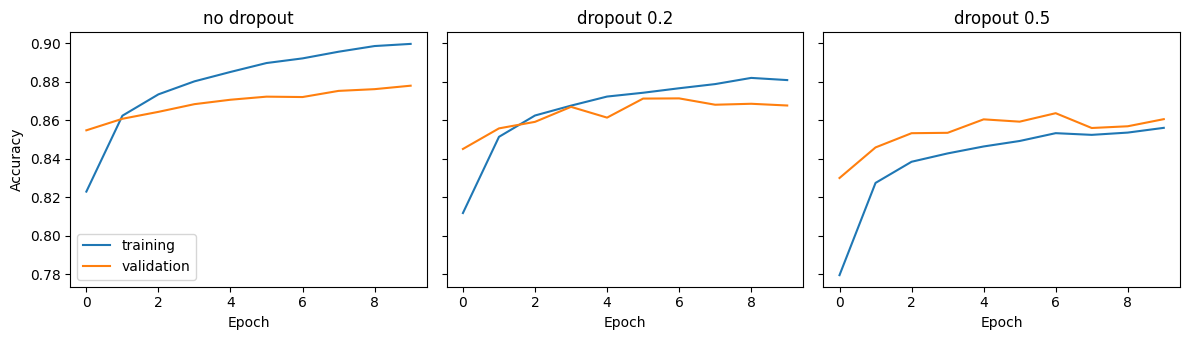

In [45]:
# Dropout experiment: summary table and training vs. validation accuracy
histories = {"no dropout": history_11, "dropout 0.2": history_12, "dropout 0.5": history_13}

print("Model       | Train acc | Val acc | Val loss")
for name, h in histories.items():
    print(f"{name:11} | {h.history['accuracy'][-1]:.4f}    | "
          f"{h.history['val_accuracy'][-1]:.4f}  | {h.history['val_loss'][-1]:.4f}")

fig, axes = plt.subplots(1, len(histories), figsize=(4*len(histories), 3.5), sharey=True)
for ax, (name, h) in zip(axes, histories.items()):
    ax.plot(h.history['accuracy'], label='training')
    ax.plot(h.history['val_accuracy'], label='validation')
    ax.set_title(name)
    ax.set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
plt.tight_layout()
plt.show()

Dropout did not help here. A rate of 0.2 was better than 0.5, but both were worse than no dropout. The model overfits only slightly, so there is little for dropout to fix, and with only 10 epochs the extra noise mostly slows learning. Dropout 0.2 is the best of the dropout values tested, but I choose no dropout for the final model.

Final configuration: one hidden layer of 128 neurons, Adam with learning rate 0.001, L2(0.0001) regularization, no dropout.